# Rotations as exponentials of Pauli operators

Every gate so far has been fixed: $X$, $Z$, $H$, $S$, $\sqrt{X}$. The phase
gate $P(\varphi)$ from Notebook 04 was the exception, a whole family of gates
with a dial, the angle $\varphi$. The algorithms in Unit 2 and the
applications in Unit 3 need many such dials: gates whose angle can be set to
any value, in circuits where a classical optimizer (an ordinary program that
adjusts numbers to make a computed score as small as possible) turns the dials
until the answer is good.

This notebook answers three questions. How do we build a gate with an
adjustable angle around any axis of the Bloch sphere, out of the operators we
already have? What does such a gate do to the state? And how do we run one
circuit at many angles in a single job?

## Before you start

This notebook uses:

- the Execution and Analysis steps and the scatter rule from
  [Notebook 00](00_Bits_and_Basis_States.ipynb);
- the Pauli operators $X$ and $Z$, and the fact $X^2 = I$
  ([Notebook 01](01_One_Bit_Operators.ipynb));
- CX, the subscript notation $A_k$ for an operator on qubit $k$, and
  commuting operators ([Notebook 02](02_Reversible_Logic.ipynb));
- amplitudes, the Born rule for one and for several qubits, the Pauli
  operator $Y = i(a^\dagger - a)$, the phase gate
  $P(\varphi) = \bar n + e^{i\varphi} n$, global phase, unitary operators, the
  Bloch sphere with its six standard states, and Qiskit's `Statevector`
  ([Notebook 04](04_Amplitudes_and_Phase.ipynb));
- the freedom to choose the phase of $|s_\perp\rangle$ when building a gate
  from two states ([Notebook 05](05_Rotation_From_Outer_Product.ipynb));
- $\sqrt{X}$ (SX) and the X-basis measurement, an $H$ followed by a Z-basis
  measurement ([Notebook 06](06_Interference_H_vs_SX.ipynb)).

It also uses the power series of the exponential, cosine, and sine,
$e^{u} = \sum_k u^k/k!$, $\cos u = 1 - u^2/2! + u^4/4! - \cdots$ and
$\sin u = u - u^3/3! + u^5/5! - \cdots$, the series that give Euler's formula.

Quick check:

1. What is $X^2$?
2. A qubit is in $\cos(\pi/8)|0\rangle + \sin(\pi/8)|1\rangle$. What is the
   probability of measuring 1?
3. Where on the Bloch sphere is $|+\rangle$?

Answers: $I$; $\sin^2(\pi/8) \approx 0.146$; on the $+x$ axis, at polar angle
$\theta = \pi/2$ and azimuth $\varphi = 0$.

After this notebook you will be able to:

1. Compute the matrix of the gate that turns a qubit about the $x$, $y$, or
   $z$ axis of the Bloch sphere by any angle.
2. Predict where such a gate moves a state on the Bloch sphere, and the
   measurement probabilities that follow.
3. Build a two-qubit gate that applies a phase set by whether the two bits
   are equal, from CX and a one-qubit gate.
4. Write one circuit with an adjustable angle and run it at many angles in
   one job.

## Setup

The same setup as every notebook in this unit: the simulator by default, and
`ibm_rensselaer` when `skip_hardware=False`.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from scipy.linalg import expm

# _runtime.py (in ../scripts) decides where circuits run:
# Aer, and IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## The exponential of a matrix

For a number $u$, Euler's formula $e^{i\varphi} = \cos\varphi + i\sin\varphi$
comes from the power series of $e^{u}$. A matrix can be put into the same
series, because a square matrix can be multiplied by itself and added. For a
diagonal matrix the result has a short closed form: every power of
$\mathrm{diag}(d_0, d_1)$ is $\mathrm{diag}(d_0^k, d_1^k)$, so the series
works on each diagonal entry separately and gives
$\mathrm{diag}(e^{d_0}, e^{d_1})$.

The *matrix exponential* of a square matrix $M$ is

$$e^{M} = I + M + \frac{M^2}{2!} + \frac{M^3}{3!} + \cdots = \sum_{k=0}^{\infty} \frac{M^k}{k!}.$$

In words: the same power series as for a number, with $M^0 = I$ in place of 1.
SciPy computes it with `scipy.linalg.expm`.

For a general matrix the series has no short closed form. For the Pauli
operators it does, because each one squares to the identity:

$$X^2 = Y^2 = Z^2 = I.$$

$X^2 = I$ is from Notebook 01, and $Z^2 = I$ because $Z = \mathrm{diag}(1, -1)$.
For $Y$, use $Y = i(a^\dagger - a)$:

$$Y^2 = i^2\,(a^\dagger - a)^2 = -\big((a^\dagger)^2 - a^\dagger a - a a^\dagger + a^2\big) = -(0 - n - \bar n + 0) = n + \bar n = I.$$

The second step expands the square, keeping the order of each product. The
third uses $(a^\dagger)^2 = a^2 = 0$ (setting or clearing a bit twice always
fails), $a^\dagger a = n$ and $a a^\dagger = \bar n$. The last uses
$n + \bar n = I$ from Notebook 01.

### Example 1: the exponential of a Pauli operator

**Problem.** Let $P$ be any matrix with $P^2 = I$, and $\theta$ a real number.
Find a closed form for $e^{-i\theta P/2}$.

**Plan.** Write the series, sort its terms by whether the power of $P$ is
even or odd, and recognize the cosine and sine series.

**Solution.**

**Subgoal 1: reduce every power of $P$.**

1. Write $\phi = \theta/2$ to shorten the formulas, so we need $e^{-i\phi P}$.
2. By the definition, $e^{-i\phi P} = \sum_k (-i\phi)^k P^k / k!$.
3. Use $P^2 = I$ repeatedly: $P^k = I$ when $k$ is even and $P^k = P$ when
   $k$ is odd.

**Subgoal 2: sum the even terms.**

4. The even terms are $k = 2m$, with $(-i\phi)^{2m} = (-1)^m \phi^{2m}$
   because $(-i)^2 = -1$.
5. So the even terms are $\big(1 - \phi^2/2! + \phi^4/4! - \cdots\big) I$, the
   cosine series: $\cos\phi \; I$.

**Subgoal 3: sum the odd terms.**

6. The odd terms are $k = 2m + 1$, with
   $(-i\phi)^{2m+1} = -i\,(-1)^m \phi^{2m+1}$.
7. So the odd terms are $-i\big(\phi - \phi^3/3! + \cdots\big) P$, the sine
   series: $-i\sin\phi \; P$.

**Subgoal 4: combine.**

8. Add the two parts and put $\phi = \theta/2$ back:

$$e^{-i\theta P/2} = \cos(\theta/2)\, I - i \sin(\theta/2)\, P.$$

**Check.** At $\theta = 0$ the right side is $I$, as $e^{0} = I$ requires. For
$P = Z = \mathrm{diag}(1, -1)$ the right side is
$\mathrm{diag}(e^{-i\theta/2}, e^{i\theta/2})$, which matches the rule for
diagonal matrices. The code below compares the formula with SciPy's `expm`.

**Self-explanation prompt.** Where did the proof use $P^2 = I$, and what would
change for a matrix that does not satisfy it? **Answer.** In step 3. Without
it the powers of $P$ do not reduce to $I$ and $P$, and the series does not
split into a cosine part and a sine part.

**Takeaway.** For any Pauli operator, the exponential needs no series: it is
$\cos(\theta/2)$ times the identity minus $i\sin(\theta/2)$ times the operator.

In [2]:
I2 = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Z = np.diag([1, -1])
a = np.array([[0, 1], [0, 0]])
Y = 1j * (a.T - a)                     # Y = i(a_dag - a), Notebook 04

theta = 1.3
for name, P in [("X", X), ("Y", Y), ("Z", Z)]:
    by_series = expm(-1j * theta * P / 2)
    by_formula = np.cos(theta / 2) * I2 - 1j * np.sin(theta / 2) * P
    squares_to_I = np.allclose(P @ P, I2)
    formula_ok = np.allclose(by_series, by_formula)
    print(f"{name}: P @ P == I: {squares_to_I}   formula matches expm: {formula_ok}")

X: P @ P == I: True   formula matches expm: True
Y: P @ P == I: True   formula matches expm: True
Z: P @ P == I: True   formula matches expm: True


**Check.** Use Example 1 to find $e^{-i\pi X/2}$.

## Rotation gates

The *rotation gate* about the Pauli operator $P$, by the angle $\theta$, is

$$R_P(\theta) = e^{-i\theta P/2} = \cos(\theta/2)\, I - i \sin(\theta/2)\, P.$$

For the three Pauli operators Example 1 gives

$$R_x(\theta) = \begin{pmatrix}\cos\frac\theta2 & -i\sin\frac\theta2\\ -i\sin\frac\theta2 & \cos\frac\theta2\end{pmatrix},\quad
R_y(\theta) = \begin{pmatrix}\cos\frac\theta2 & -\sin\frac\theta2\\ \sin\frac\theta2 & \cos\frac\theta2\end{pmatrix},\quad
R_z(\theta) = \begin{pmatrix}e^{-i\theta/2} & 0\\ 0 & e^{i\theta/2}\end{pmatrix}.$$

In words: a rotation gate is a family of gates, one for each angle $\theta$,
built from the identity and one Pauli operator. At $\theta = 0$ it is the
identity, and as $\theta$ grows it mixes in more of $P$. In $R_y$ the factor
$-i$ cancels the $i$ inside $Y$: the matrix $-iY$ has the real entries $-1$
and $1$, so $R_y(\theta)$ is a real matrix.

Each $R_P(\theta)$ is unitary. Every Pauli operator equals its own conjugate
transpose ($X$ and $Z$ are real and symmetric, and the entries $-i$ and $i$ of
$Y$ are conjugates of each other in mirrored positions). So, writing
$c = \cos(\theta/2)$ and $s = \sin(\theta/2)$, the conjugate transpose of
$cI - isP$ is $cI + isP$, and

$$(cI + isP)(cI - isP) = c^2 I - ics\,P + ics\,P + s^2 P^2 = (c^2 + s^2)\,I = I,$$

using $P^2 = I$ and $\cos^2 + \sin^2 = 1$. Qiskit applies the rotation gates with `circuit.rx(theta, k)`,
`circuit.ry(theta, k)` and `circuit.rz(theta, k)`.

### Example 2: $R_y(\theta)$ acting on $|0\rangle$

**Problem.** Compute $R_y(\theta)|0\rangle$, its measurement probabilities,
and its place on the Bloch sphere.

**Plan.** Multiply the matrix by $(1, 0)^T$, then compare with the Bloch-sphere
form $\cos(\vartheta/2)|0\rangle + e^{i\varphi}\sin(\vartheta/2)|1\rangle$
from Notebook 04. (We write the Bloch polar angle as $\vartheta$ here so it
cannot be confused with the gate angle $\theta$.)

**Solution.**

**Subgoal 1: the state.**

1. The first column of $R_y(\theta)$ is what it does to $|0\rangle$:
   $R_y(\theta)|0\rangle = \cos(\theta/2)|0\rangle + \sin(\theta/2)|1\rangle$.

**Subgoal 2: the probabilities.**

2. By the Born rule, $P(0) = \cos^2(\theta/2)$ and $P(1) = \sin^2(\theta/2)$.

**Subgoal 3: the Bloch-sphere position.**

3. Match the amplitudes with the Bloch form: $\vartheta = \theta$ and
   $\varphi = 0$ (both amplitudes are real and, for $0 \le \theta \le \pi$,
   not negative).

**Check.** At $\theta = \pi$ the state is $|1\rangle$ and $P(1) = 1$. At
$\theta = \pi/2$ it is $(|0\rangle + |1\rangle)/\sqrt2 = |+\rangle$, on the
$+x$ axis.

**Takeaway.** $R_y(\theta)$ tilts $|0\rangle$ away from the north pole by the
angle $\theta$, toward the $+x$ axis. This is why the matrix uses
$\theta/2$: the amplitudes of a Bloch-sphere state are written with half the
polar angle, so a gate written with $\theta/2$ moves the state by the full
angle $\theta$ on the sphere.

### Example 3: $R_z(\alpha)$ turns a state about the $z$ axis

**Problem.** Apply $R_z(\alpha)$ to a general state
$\cos(\vartheta/2)|0\rangle + e^{i\varphi}\sin(\vartheta/2)|1\rangle$ and
find its new Bloch-sphere angles.

**Plan.** $R_z(\alpha)$ is diagonal, so it multiplies each amplitude by one
number. Factor out a global phase and read off the angles.

**Solution.**

**Subgoal 1: apply the gate.**

1. Multiply the $|0\rangle$ amplitude by $e^{-i\alpha/2}$ and the $|1\rangle$
   amplitude by $e^{i\alpha/2}$:
   $e^{-i\alpha/2}\cos(\vartheta/2)|0\rangle + e^{i\alpha/2}e^{i\varphi}\sin(\vartheta/2)|1\rangle$.

**Subgoal 2: put it back in Bloch form.**

2. Factor $e^{-i\alpha/2}$ out of both terms. The second term keeps
   $e^{i\alpha/2}e^{i\alpha/2}e^{i\varphi} = e^{i(\varphi + \alpha)}$:
   $e^{-i\alpha/2}\big(\cos(\vartheta/2)|0\rangle + e^{i(\varphi+\alpha)}\sin(\vartheta/2)|1\rangle\big)$.
3. The factor $e^{-i\alpha/2}$ is a global phase, which changes no
   measurement (Notebook 04), so the state is the one with polar angle
   $\vartheta$ and azimuth $\varphi + \alpha$.

**Check.** With $\vartheta = \pi/2$, $\varphi = 0$ (the state $|+\rangle$) and
$\alpha = \pi/2$, the azimuth becomes $\pi/2$: the state $|{+i}\rangle$, a
quarter turn from $+x$ to $+y$.

**Takeaway.** $R_z(\alpha)$ keeps the polar angle and adds $\alpha$ to the
azimuth: it turns the whole Bloch sphere by $\alpha$ about the $z$ axis.

Examples 2 and 3 are two cases of one rule: $R_P(\theta)$ turns the Bloch
sphere by the angle $\theta$ about the axis of $P$. The axes are the ones
from Notebook 04: $z$ through $|0\rangle$ and $|1\rangle$, $x$ through
$|\pm\rangle$, $y$ through $|{\pm i}\rangle$. The direction follows the
right-hand rule: with the right thumb along the positive axis, the fingers
curl in the direction of a positive $\theta$.

This notebook does not prove the rule in general. Example 3 proves it for
$R_z$ on every state. Example 2 shows it for $R_y$ on one state, $|0\rangle$.
The code below checks four more cases, including the direction of the turn.
From here on the rule is taken as given; Notebook 10 adds a way to read a
state's Bloch-sphere point from measurements, which makes the rule testable
on any state.

The code uses two `Statevector` tools. `Statevector.from_label(label)` makes a
one-qubit state from a label: `"0"`, `"1"`, `"+"`, `"-"`, `"r"` for
$|{+i}\rangle$ and `"l"` for $|{-i}\rangle$ (a longer label such as `"01"`
gives a bitstring, bit 0 on the right). `state.evolve(circuit)` returns the
state after the circuit's gates act on it.

In [3]:
from qiskit.quantum_info import Statevector


def bloch_angles(state):
    """Polar angle and azimuth (in units of pi) of a one-qubit state."""
    alpha, beta = state.data
    theta = 2 * np.arccos(min(abs(alpha), 1.0))
    phi = (np.angle(beta) - np.angle(alpha)) % (2 * np.pi) if abs(beta) > 1e-9 else 0.0
    return float(round(theta / np.pi, 3)), float(round(phi / np.pi, 3))


cases = [
    ("Ry(pi/2) |0>  (expect +x: 0.5, 0.0)", "ry", np.pi / 2, "0"),
    ("Rx(pi/2) |0>  (expect -y: 0.5, 1.5)", "rx", np.pi / 2, "0"),
    ("Rz(pi/2) |+>  (expect +y: 0.5, 0.5)", "rz", np.pi / 2, "+"),
    ("Rz(pi)   |+>  (expect -x: 0.5, 1.0)", "rz", np.pi, "+"),
]
for text, gate, angle, start in cases:
    circuit = QuantumCircuit(1)
    getattr(circuit, gate)(angle, 0)
    state = Statevector.from_label(start).evolve(circuit)
    print(f"{text}:  theta/pi, phi/pi = {bloch_angles(state)}")

Ry(pi/2) |0>  (expect +x: 0.5, 0.0):  theta/pi, phi/pi = (0.5, 0.0)
Rx(pi/2) |0>  (expect -y: 0.5, 1.5):  theta/pi, phi/pi = (0.5, 1.5)
Rz(pi/2) |+>  (expect +y: 0.5, 0.5):  theta/pi, phi/pi = (0.5, 0.5)
Rz(pi)   |+>  (expect -x: 0.5, 1.0):  theta/pi, phi/pi = (0.5, 1.0)


The rotation gates contain the gates of Notebooks 04 and 06, up to a global
phase. Compare $R_z(\theta) = \mathrm{diag}(e^{-i\theta/2}, e^{i\theta/2})$
with $P(\theta) = \mathrm{diag}(1, e^{i\theta})$: multiplying $P(\theta)$ by
$e^{-i\theta/2}$ gives $R_z(\theta)$. So $R_z(\theta) = e^{-i\theta/2}P(\theta)$,
and $S = P(\pi/2)$ and $Z = P(\pi)$ are turns of a quarter and a half about
$z$. In the same way, $\sqrt{X} = e^{i\pi/4} R_x(\pi/2)$: SX is a quarter turn
about $x$. Qiskit's `Operator(...).equiv(...)` tests whether two gates are
equal up to a global phase.

In [4]:
from qiskit.circuit.library import PhaseGate, RXGate, RZGate, SXGate
from qiskit.quantum_info import Operator

angle = 0.7
rz = Operator(RZGate(angle)).data
phase = Operator(PhaseGate(angle)).data
rz_matches = np.allclose(rz, np.exp(-1j * angle / 2) * phase)
print("Rz(0.7) == e^{-i 0.35} P(0.7):", rz_matches)
sx_is_rx = Operator(SXGate()).equiv(Operator(RXGate(np.pi / 2)))
print("SX equals Rx(pi/2) up to a global phase:", sx_is_rx)
print("Rx(2 pi) =\n", Operator(RXGate(2 * np.pi)).data.real)
print("Rx(4 pi) =\n", Operator(RXGate(4 * np.pi)).data.real)

Rz(0.7) == e^{-i 0.35} P(0.7): True
SX equals Rx(pi/2) up to a global phase: True
Rx(2 pi) =
 [[-1.  0.]
 [ 0. -1.]]
Rx(4 pi) =
 [[1. 0.]
 [0. 1.]]


The last two printouts refute a common mistake. It is tempting to think that
$R_x(2\pi) = I$, because a full turn brings every point of the Bloch sphere
back to where it started, as a full turn of a wheel does. That is wrong.
Example 1 gives $R_x(2\pi) = \cos(\pi) I - i\sin(\pi) X = -I$. The extra
$-1$ is a global phase, so on its own a full turn changes no measurement;
only $R_x(4\pi) = I$. The sign does matter when the rotation is applied only
on some branches of a computation, as in the controlled gates of Unit 2,
where a global phase of one qubit becomes a relative phase of another.

**Check.** Which rotation gate, and which angle, takes $|0\rangle$ to $|1\rangle$
with real amplitudes all the way?

## A rotation on two qubits: $R_{zz}$

The quantum approximate optimization algorithm (QAOA) in Unit 2 and the
optimization problems in Unit 3 need a gate that does something different
when two bits are equal and when they differ. Start from the classical idea.

The *parity* of a bitstring is the XOR of its bits: 0 (even) when it has an
even number of 1s, 1 (odd) when it has an odd number. For two bits, the
parity is $x_1 \oplus x_0$: 0 when the bits are equal and 1 when they differ.

The two-qubit operator $Z_1 Z_0$ reads the parity. $Z$ multiplies a bit by
$1 - 2x$ (Notebook 01), so

$$Z_1 Z_0 |x_1 x_0\rangle = (1 - 2x_1)(1 - 2x_0)\,|x_1 x_0\rangle,$$

which is $+1$ times the state for $00$ and $11$ and $-1$ times the state for
$01$ and $10$. And $(Z_1Z_0)^2 = Z_1^2 Z_0^2 = I$, because operators on
different qubits commute (Notebook 02), so the two $Z_1$ factors can be brought
together. So Example 1 applies, and

$$R_{zz}(\theta) = e^{-i\theta Z_1 Z_0/2} = \cos(\theta/2)\, I - i\sin(\theta/2)\, Z_1 Z_0$$

is diagonal: it multiplies even-parity bitstrings by $e^{-i\theta/2}$ and
odd-parity ones by $e^{+i\theta/2}$. Qiskit applies it with
`circuit.rzz(theta, 0, 1)`.

### Example 4: $R_{zz}$ from CX and $R_z$

**Problem.** Show that the circuit CX (control 0, target 1), then
$R_z(\theta)$ on qubit 1, then the same CX again equals $R_{zz}(\theta)$.

**Plan.** Follow one bitstring $|x_1 x_0\rangle$ through the three gates.
Since all three map bitstrings to (phases times) bitstrings, one input at a
time is enough.

**Solution.**

**Subgoal 1: write the parity into qubit 1.**

1. CX adds bit 0 to bit 1 with XOR (Notebook 02):
   $|x_1 x_0\rangle \to |x_1 \oplus x_0,\; x_0\rangle$. Bit 1 now holds the
   parity.

**Subgoal 2: apply the phase.**

2. $R_z(\theta) = \mathrm{diag}(e^{-i\theta/2}, e^{i\theta/2})$ on qubit 1
   multiplies the state by $e^{-i\theta/2}$ when bit 1 is 0 (even parity)
   and by $e^{+i\theta/2}$ when it is 1 (odd parity).

**Subgoal 3: restore qubit 1.**

3. The second CX gives $|(x_1 \oplus x_0) \oplus x_0,\; x_0\rangle = |x_1 x_0\rangle$,
   because $x_0 \oplus x_0 = 0$. The phase from step 2 stays.

**Check.** Each bitstring comes back unchanged except for $e^{-i\theta/2}$
(even) or $e^{+i\theta/2}$ (odd), which is exactly $R_{zz}(\theta)$. The code
below compares the two matrices with `Operator`.

**Takeaway.** A CX pair computes the parity into one qubit and then uncomputes
it, and the one-qubit rotation in between turns that parity into a phase. The
same pattern, with more CX gates, gives the rotation for any product of $Z$
operators on several qubits, such as $Z_2 Z_1 Z_0$.

CX, Rz, CX == RZZ: True
diagonal of RZZ(0.9) for 00, 01, 10, 11: [0.9-0.435j 0.9+0.435j 0.9+0.435j 0.9-0.435j]
e^{-i 0.45} = (0.9-0.435j)


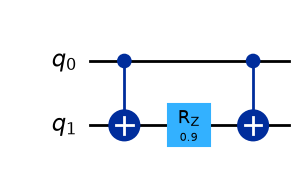

In [5]:
from qiskit.circuit.library import RZZGate

angle = 0.9
built = QuantumCircuit(2)
built.cx(0, 1)
built.rz(angle, 1)
built.cx(0, 1)
rzz = Operator(RZZGate(angle)).data
print("CX, Rz, CX == RZZ:", np.allclose(Operator(built).data, rzz))
print("diagonal of RZZ(0.9) for 00, 01, 10, 11:", np.round(np.diag(rzz), 3))
print("e^{-i 0.45} =", np.round(np.exp(-1j * angle / 2), 3))
built.draw("mpl")

In Unit 2, QAOA applies one $R_{zz}$ per edge of a graph, and the
variational algorithms (circuits whose angles a classical optimizer tunes)
build their circuits from layers of $R_y$ and CX.
Every one of those gates is a rotation from this notebook.

**Check.** What does $R_{zz}(\pi)$ do to $|01\rangle$?

## Circuits with an adjustable angle

A rotation is only useful as a dial if we can turn the dial without
rebuilding the circuit. A *circuit parameter* is a named placeholder, created
with Qiskit's `Parameter`, that stands in a circuit where a number would go.
The circuit is built and transpiled once, with the placeholder in place, and
numbers are supplied only when it runs.

A *parameter sweep* runs the same circuit at many values of its parameters.
The PUB for a sweep is a tuple `(circuit, values)`, where `values` is an array
with one row per point of the sweep and one column per parameter. A circuit
with one parameter, swept over 9 angles, takes an array of shape `(9, 1)`, and
one PUB runs all 9.

## The experiment: $R_y$ versus $R_x$

Example 2 showed $P(1) = \sin^2(\theta/2)$ for $R_y(\theta)|0\rangle$. The
same matrix calculation for $R_x(\theta)|0\rangle$ (first column of $R_x$)
gives $\cos(\theta/2)|0\rangle - i\sin(\theta/2)|1\rangle$, with the same
$P(1) = \sin^2(\theta/2)$. Are the two states the same? A Z-basis measurement
cannot tell. The experiment sweeps $\theta$ for both gates and measures in the
Z basis and in the X basis.

### Example 5: predicting the X-basis results

**Problem.** For $R_y(\theta)|0\rangle$ and $R_x(\theta)|0\rangle$, find the
probability of the outcome 0 in an X-basis measurement.

**Plan.** An X-basis measurement applies $H$ and then measures in the Z basis
(Notebook 06), so outcome 0 means the state was found in $|+\rangle$. Its
probability is the overlap $|\langle +|\psi\rangle|^2$ (Notebook 04).

**Solution.**

**Subgoal 1: the $R_y$ state.**

1. $\langle +|\psi\rangle = \tfrac{1}{\sqrt2}(\cos\tfrac\theta2 + \sin\tfrac\theta2)$,
   since $\langle +| = (1, 1)/\sqrt2$ and both amplitudes are real.
2. Square it: $\tfrac12(\cos^2\tfrac\theta2 + 2\sin\tfrac\theta2\cos\tfrac\theta2 + \sin^2\tfrac\theta2)$.
3. Use $\cos^2 + \sin^2 = 1$ and $2\sin u\cos u = \sin 2u$:
   $P(0) = \tfrac12(1 + \sin\theta)$.

**Subgoal 2: the $R_x$ state.**

4. $\langle +|\psi\rangle = \tfrac{1}{\sqrt2}(\cos\tfrac\theta2 - i\sin\tfrac\theta2)$.
5. The squared modulus of $u - iv$ for real $u$, $v$ is $u^2 + v^2$, so
   $P(0) = \tfrac12(\cos^2\tfrac\theta2 + \sin^2\tfrac\theta2) = \tfrac12$
   for every $\theta$.

**Check.** At $\theta = \pi/2$, $R_y$ gives $|+\rangle$ and $P(0) = 1$, while
$R_x$ gives $|{-i}\rangle$ (on the $-y$ axis, as the Bloch-angle check above
showed), which an X-basis measurement splits 50/50.

**Takeaway.** The two states have the same Z-basis probabilities but sit on
different meridians of the Bloch sphere: $R_y$ turns $|0\rangle$ toward $+x$,
$R_x$ turns it toward $-y$. A measurement along $x$ tells them apart.

### Encoding

Every qubit starts in $|0\rangle$, which is the starting state here. Nothing
else is needed.

### Operator

One parameterized rotation, $R_y(\theta)$ or $R_x(\theta)$, then either a
Z-basis measurement or an X-basis measurement ($H$ first). That makes four
circuits, each with the single parameter `theta`.

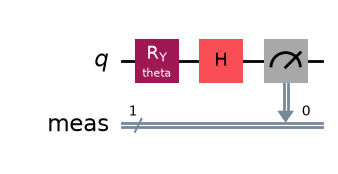

In [6]:
from qiskit.circuit import Parameter

THETA = Parameter("theta")
# One row per point of the sweep, one column per parameter.
THETA_VALUES = np.linspace(0, 2 * np.pi, 9).reshape(-1, 1)


def rotation_circuit(gate, basis):
    qubits = QuantumRegister(1, name="q")
    bits = ClassicalRegister(1, name="meas")
    circuit = QuantumCircuit(qubits, bits, name=f"{gate}_{basis}")
    getattr(circuit, gate)(THETA, qubits[0])
    if basis == "X":
        circuit.h(qubits[0])                 # X-basis measurement, Notebook 06
    circuit.measure(qubits, bits)
    return circuit


names = [("ry", "Z"), ("ry", "X"), ("rx", "Z"), ("rx", "X")]
circuits = {name: rotation_circuit(*name) for name in names}
circuits[("ry", "X")].draw("mpl")

### Execution

Each circuit is transpiled once, with `theta` still a placeholder. Each PUB
is `(isa_circuit, THETA_VALUES)`, so four PUBs carry all 36 runs in one job.

In [7]:
pubs = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    pubs[target.label] = [
        (pass_manager.run(c), THETA_VALUES) for c in circuits.values()
    ]

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    results[target.label] = target.wait(job)

### Analysis

For a swept PUB, `.data.meas` holds one set of shots per row of
`THETA_VALUES`, and `get_counts(i)` returns the counts of row `i`. The table
compares the measured probabilities with the predictions of Examples 2 and 5:
$P(1) = \sin^2(\theta/2)$ in the Z basis for both gates, and in the X basis
$P(0) = (1 + \sin\theta)/2$ for $R_y$ and $1/2$ for $R_x$.

In [8]:
thetas = THETA_VALUES[:, 0]
predicted = {
    ("ry", "Z"): np.sin(thetas / 2) ** 2,           # P(1)
    ("rx", "Z"): np.sin(thetas / 2) ** 2,           # P(1)
    ("ry", "X"): (1 + np.sin(thetas)) / 2,          # P(0)
    ("rx", "X"): np.full_like(thetas, 0.5),         # P(0)
}
outcome = {"Z": "1", "X": "0"}

measured = {}
for label, result in results.items():
    if result is None:
        continue
    measured[label] = {}
    for name, pub_result in zip(circuits, result):
        bits = pub_result.data.meas
        hits = [bits.get_counts(i).get(outcome[name[1]], 0) for i in range(len(thetas))]
        measured[label][name] = np.array(hits) / SETTINGS.shots
    print(f"{label}, {SETTINGS.shots} shots per angle")
    print("  theta/pi   Ry: P(1) Z / pred   P(0) X / pred"
          "     Rx: P(1) Z / pred   P(0) X / pred")
    for i, t in enumerate(thetas):
        row = [f"{measured[label][n][i]:.3f} / {predicted[n][i]:.3f}" for n in names]
        ry_part = f"{row[0]}     {row[1]}"
        rx_part = f"{row[2]}     {row[3]}"
        print(f"  {t / np.pi:7.3f}     {ry_part}         {rx_part}")

aer, 4096 shots per angle
  theta/pi   Ry: P(1) Z / pred   P(0) X / pred     Rx: P(1) Z / pred   P(0) X / pred
    0.000     0.000 / 0.000     0.486 / 0.500         0.000 / 0.000     0.496 / 0.500
    0.250     0.148 / 0.146     0.866 / 0.854         0.142 / 0.146     0.497 / 0.500
    0.500     0.514 / 0.500     1.000 / 1.000         0.493 / 0.500     0.510 / 0.500
    0.750     0.845 / 0.854     0.859 / 0.854         0.858 / 0.854     0.501 / 0.500
    1.000     1.000 / 1.000     0.500 / 0.500         1.000 / 1.000     0.499 / 0.500
    1.250     0.851 / 0.854     0.143 / 0.146         0.856 / 0.854     0.508 / 0.500
    1.500     0.508 / 0.500     0.000 / 0.000         0.500 / 0.500     0.497 / 0.500
    1.750     0.142 / 0.146     0.149 / 0.146         0.143 / 0.146     0.503 / 0.500
    2.000     0.000 / 0.000     0.510 / 0.500         0.000 / 0.000     0.512 / 0.500


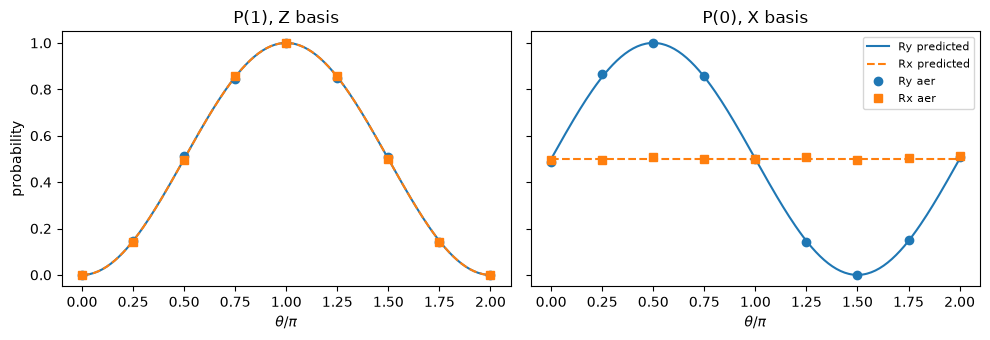

In [9]:
fine = np.linspace(0, 2 * np.pi, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, basis, curve_y, curve_x, ylabel in [
    (axes[0], "Z", np.sin(fine / 2) ** 2, np.sin(fine / 2) ** 2, "P(1), Z basis"),
    (axes[1], "X", (1 + np.sin(fine)) / 2, np.full_like(fine, 0.5), "P(0), X basis"),
]:
    ax.plot(fine / np.pi, curve_y, "C0-", label="Ry predicted")
    ax.plot(fine / np.pi, curve_x, "C1--", label="Rx predicted")
    for label, values in measured.items():
        ax.plot(thetas / np.pi, values[("ry", basis)], "C0o", label=f"Ry {label}")
        ax.plot(thetas / np.pi, values[("rx", basis)], "C1s", label=f"Rx {label}")
    ax.set_xlabel(r"$\theta / \pi$")
    ax.set_title(ylabel)
axes[0].set_ylabel("probability")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In the Z basis the two gates give the same curve, $\sin^2(\theta/2)$. In the
X basis they separate: $R_y$ follows $(1 + \sin\theta)/2$ and $R_x$ stays at
$1/2$. The simulator has no errors, but each probability comes from a
finite number of shots, so it scatters around the prediction. The scatter
$\sqrt{p(1-p)/N}$ is at most 0.008 for $N = 4096$ shots (at $p = 0.5$) and 0
where the prediction is exactly 0 or 1. By the scatter rule of Notebook 00,
most points land within twice the scatter of the curve, and with 36 points
in the table one or two at two to three times the scatter are expected by
chance. Each run gives a different set of small deviations.

## Exercises

1. Compute $R_y(\pi/3)|0\rangle$ and the probability of measuring 1.
2. Write the matrix $R_z(\pi/2)$ and find the number $c$ with
   $S = c\, R_z(\pi/2)$.
3. Show that $R_x(\theta_1)\,R_x(\theta_2) = R_x(\theta_1 + \theta_2)$ by
   multiplying the closed forms from Example 1 and using the angle-addition
   formulas for cosine and sine.
4. Find $R_{zz}(\pi)$ as a multiple of $Z_1 Z_0$, and say what it does to each
   of the four bitstrings.
5. Notebook 05 built gates that take $|0\rangle$ to $|+\rangle$. Show that
   $R_y(\pi/2)$ and $H$ both do, and find the one-qubit gate $G$ with
   $H = R_y(\pi/2)\, G$.
6. True or false: since $R_x(\theta)|0\rangle$ and $R_y(\theta)|0\rangle$ give
   the same Z-basis counts at every angle, they are the same state. Give the
   reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   experiment on `ibm_rensselaer`. The difference between the largest and the
   smallest measured $P(1)$ in the Z-basis $R_y$ sweep is the contrast; it is
   1 for an error-free machine. What contrast do you measure, and is its gap
   from 1 larger than the random scatter of a probability near 0 or 1?
8. (hardware) Build the circuit $H$ on both qubits, $R_{zz}(\theta)$, then $H$
   on both qubits and measure. Predict $P(00)$ as a function of $\theta$ with
   `Statevector`, then sweep $\theta$ from 0 to $\pi$ on the simulator and on
   hardware. Which points deviate most on hardware?

## What you can now do

1. Compute $R_x(\theta)$, $R_y(\theta)$ and $R_z(\theta)$ from
   $e^{-i\theta P/2} = \cos(\theta/2) I - i\sin(\theta/2) P$.
2. Predict where a rotation moves a state on the Bloch sphere, and the
   measurement probabilities in the Z and X bases.
3. Build $R_{zz}(\theta)$ from two CX gates and an $R_z$, and say which
   bitstrings get which phase.
4. Write a circuit with a `Parameter` and sweep it in one PUB.

## Solutions

**Check, matrix exponential.** With $\theta = \pi$ and $P = X$:
$\cos(\pi/2) I - i\sin(\pi/2) X = -iX$.

**Check, rotation gates.** $R_y(\pi)$: by Example 2, $R_y(\theta)|0\rangle$
has the real amplitudes $\cos(\theta/2)$ and $\sin(\theta/2)$ at every angle,
and at $\theta = \pi$ it is $|1\rangle$.

**Check, $R_{zz}$.** $|01\rangle$ has odd parity, so $R_{zz}(\pi)$ multiplies
it by $e^{i\pi/2} = i$.

**Exercise 1.** Example 2 with $\theta = \pi/3$:
$\cos(\pi/6)|0\rangle + \sin(\pi/6)|1\rangle = \tfrac{\sqrt3}{2}|0\rangle + \tfrac12|1\rangle$.
$P(1) = (1/2)^2 = 0.250$. **Check.** $0.750 + 0.250 = 1$.

**Exercise 2.** $R_z(\pi/2) = \mathrm{diag}(e^{-i\pi/4}, e^{i\pi/4})$.
$S = P(\pi/2) = \mathrm{diag}(1, i)$. Multiply $R_z(\pi/2)$ by $e^{i\pi/4}$:
$\mathrm{diag}(1, e^{i\pi/2}) = \mathrm{diag}(1, i) = S$. So $c = e^{i\pi/4}$,
which matches $R_z(\theta) = e^{-i\theta/2} P(\theta)$.

**Exercise 3.** Write $c_k = \cos(\theta_k/2)$ and $s_k = \sin(\theta_k/2)$.

1. Multiply: $(c_1 I - i s_1 X)(c_2 I - i s_2 X) = c_1c_2 I - i(c_1 s_2 + s_1 c_2) X + (-i)^2 s_1 s_2 X^2$.
2. Use $X^2 = I$ and $(-i)^2 = -1$: $(c_1 c_2 - s_1 s_2) I - i(s_1 c_2 + c_1 s_2) X$.
3. Angle addition: $c_1c_2 - s_1s_2 = \cos\frac{\theta_1+\theta_2}{2}$ and
   $s_1c_2 + c_1s_2 = \sin\frac{\theta_1+\theta_2}{2}$, so the product is
   $R_x(\theta_1 + \theta_2)$.

**Check.** With $\theta_2 = -\theta_1$ the product is $R_x(0) = I$, so
$R_x(-\theta)$ undoes $R_x(\theta)$.

**Exercise 4.** Example 1 with $\theta = \pi$ and $P = Z_1Z_0$:
$R_{zz}(\pi) = \cos(\pi/2) I - i\sin(\pi/2) Z_1Z_0 = -i\,Z_1 Z_0$. It multiplies
$|00\rangle$ and $|11\rangle$ by $-i$ and $|01\rangle$ and $|10\rangle$ by $+i$.
Up to the global phase $-i$, it is $Z_1Z_0$: a sign flip on the odd-parity
bitstrings.

**Exercise 5.** $H|0\rangle = |+\rangle$ (Notebook 04) and
$R_y(\pi/2)|0\rangle = |+\rangle$ (Example 2). Their matrices are
$H = \tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ and
$R_y(\pi/2) = \tfrac{1}{\sqrt2}\begin{pmatrix}1&-1\\1&1\end{pmatrix}$. The
columns of $H$ are the columns of $R_y(\pi/2)$ with the second one negated,
and negating the second column is multiplication on the right by
$Z = \mathrm{diag}(1, -1)$. So $G = Z$ and $H = R_y(\pi/2)\,Z$.

**Check.** This code returns `True`:

```python
from qiskit.circuit.library import HGate, RYGate
from qiskit.quantum_info import Operator

h_matrix = Operator(HGate()).data
ry_matrix = Operator(RYGate(np.pi / 2)).data
print(np.allclose(h_matrix, ry_matrix @ np.diag([1, -1])))
```

The two gates agree on $|0\rangle$, and they send $|1\rangle$ to $|-\rangle$
and to $-|-\rangle$, the same state with opposite signs. This is the freedom
Notebook 05 found when building a gate from two states: the phase of
$|s_\perp\rangle$ can be chosen freely. There, the recipe for $|0\rangle \to
|+\rangle$ gave $HZ$, which is $R_y(\pi/2)$, and the other sign choice gave
$H$.

**Exercise 6.** False. Both have $P(1) = \sin^2(\theta/2)$, but the relative
phase between their amplitudes differs: real for $R_y$, a factor $-i$ for
$R_x$. Example 5 and the X-basis curves show the difference: $P(0)$ is
$(1+\sin\theta)/2$ for $R_y$ and $1/2$ for $R_x$.

**Exercise 7.** Expect a contrast a few percent below 1: the lowest point
sits a little above 0 and the highest a little below 1, from readout errors
and gate errors. A probability near 0 or 1 has a small scatter: for
$p = 0.01$ and $N = 4096$, $\sqrt{p(1-p)/N} \approx 0.002$. A gap of a
percent or more is about five scatters, so by the scatter rule of Notebook 00
it is a hardware effect, not chance.

**Exercise 8.** The prediction is $P(00) = \cos^2(\theta/2)$,
$P(11) = \sin^2(\theta/2)$, and $P(01) = P(10) = 0$.

**Subgoal 1: the first $H$ layer.**

1. $H|0\rangle = \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle)$ on each qubit, and
   the tensor product of the two (Notebook 02) gives
   $\tfrac12\big(|00\rangle + |01\rangle + |10\rangle + |11\rangle\big)$.

**Subgoal 2: the phases from $R_{zz}$.**

2. $R_{zz}(\theta)$ multiplies $|00\rangle$ and $|11\rangle$ by
   $e^{-i\theta/2}$ and $|01\rangle$ and $|10\rangle$ by $e^{i\theta/2}$.
3. Factor out the global phase $e^{-i\theta/2}$:
   $\tfrac12\big(|00\rangle + e^{i\theta}|01\rangle + e^{i\theta}|10\rangle + |11\rangle\big)$.

**Subgoal 3: the second $H$ layer.**

4. On one qubit, $H|x\rangle = \tfrac{1}{\sqrt2}\big(|0\rangle + (-1)^x|1\rangle\big)$
   (Notebook 04: $H|0\rangle = |+\rangle$, $H|1\rangle = |-\rangle$). So on two
   qubits, $H$ on both sends $|x_1x_0\rangle$ to
   $\tfrac12\sum_{y_1y_0}(-1)^{x_1y_1 + x_0y_0}|y_1y_0\rangle$: every output
   bitstring gets amplitude $\pm\tfrac12$, with a minus sign for each
   position where both the input and the output bit are 1.
5. Amplitude of $|00\rangle$: every sign is $+$, so
   $\tfrac12\cdot\tfrac12\big(1 + e^{i\theta} + e^{i\theta} + 1\big) = \tfrac12(1 + e^{i\theta})$.
6. Amplitude of $|11\rangle$: the inputs $01$ and $10$ get a minus sign, so
   $\tfrac14\big(1 - e^{i\theta} - e^{i\theta} + 1\big) = \tfrac12(1 - e^{i\theta})$.
7. Amplitude of $|01\rangle$: the inputs $01$ and $11$ get a minus sign, so
   $\tfrac14\big(1 - e^{i\theta} + e^{i\theta} - 1\big) = 0$. In the same way
   the amplitude of $|10\rangle$ is $\tfrac14\big(1 + e^{i\theta} - e^{i\theta} - 1\big) = 0$.

**Subgoal 4: the probabilities.**

8. Born rule for several qubits (Notebook 04):
   $P(00) = \tfrac14|1 + e^{i\theta}|^2 = \tfrac14(2 + 2\cos\theta) = \cos^2(\theta/2)$,
   using $|1 + e^{i\theta}|^2 = (1 + e^{i\theta})(1 + e^{-i\theta})$ and
   $1 + \cos\theta = 2\cos^2(\theta/2)$. In the same way
   $P(11) = \tfrac14(2 - 2\cos\theta) = \sin^2(\theta/2)$.

**Check.** At $\theta = 0$, $R_{zz}$ is $I$ and $HH$ on each qubit returns
$|00\rangle$: $P(00) = 1$. The four probabilities add to 1. `Statevector`
gives the same numbers.

The second $H$ layer turned the relative phase between even and odd
bitstrings into probabilities, the two-qubit version of the interference in
Notebook 06. On hardware expect a few percent of the shots on $01$ and $10$,
and $P(00)$ a few percent away from $\cos^2(\theta/2)$. Expect
this circuit to deviate more than the one-qubit sweep of Exercise 7, because
the transpiled $R_{zz}$ contains two-qubit gates, which have higher error
rates than one-qubit gates; `count_ops()` on the ISA circuit shows how many.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| matrix exponential | $e^M = \sum_k M^k/k!$, the exponential power series applied to a square matrix |
| rotation gate $R_P(\theta)$ | $e^{-i\theta P/2} = \cos(\theta/2) I - i\sin(\theta/2) P$ for a Pauli operator $P$; turns the Bloch sphere by $\theta$ about the axis of $P$ |
| $R_x$, $R_y$, $R_z$ | the rotation gates about the $x$, $y$ and $z$ axes |
| parity | the XOR of the bits of a bitstring: 0 for an even number of 1s, 1 for an odd number |
| $R_{zz}(\theta)$ | $e^{-i\theta Z_1Z_0/2}$: phase $e^{-i\theta/2}$ on even-parity bitstrings and $e^{+i\theta/2}$ on odd ones |
| circuit parameter | a named placeholder (`Parameter`) in a circuit, given a number only when the circuit runs |
| parameter sweep | running one circuit at many parameter values; the PUB is `(circuit, values)` with one row of `values` per point |